# Week 9 — Operational ML: Medical Equipment Failure Risk Prediction

**Author:** Valentine Nyankwoga
**Context:** Team Vita Analytics — VitalAsset (Medical Equipment Utilization & Maintenance Risk Monitoring for Kenyan County Hospitals)

This notebook builds an **operational machine learning pipeline** that predicts whether a piece of hospital medical equipment (dialysis machine, ventilator, X-ray unit, infusion pump, anaesthesia machine, ECG monitor) is at **High Risk of failure/breakdown in the next 30 days**, using operational and sensor-style features (usage load, vibration, maintenance history, environmental stress, etc.).

The goal is not just to build an accurate classifier, but to build one that a **biomedical engineering / operations team** could actually trust and act on — hence the heavy emphasis on imbalance handling, the *right* metrics (not accuracy), and explainability (SHAP).

**Sections**
1. Problem Definition
2. Data Preparation & Class Imbalance Check
3. Model Training (Random Forest + XGBoost, Cross-Validated)
4. Evaluation (Confusion Matrix, Precision/Recall/F1, ROC-AUC)
5. Clustering (Bonus) — Equipment Risk Segments via K-Means
6. Explainability — Feature Importance + SHAP
7. Operational Takeaways


## 1. Problem Definition

**Operational problem:** Predictive Maintenance / Equipment Failure Risk (a special case of imbalanced binary classification, structurally identical to fraud detection or churn — rare, costly, high-stakes positive class).

**Target variable:** `high_risk_30d`
- `1` = equipment is at **High Risk** of a breakdown/failure event within the next 30 days
- `0` = equipment is expected to keep running normally

**Why this framing?** In a resource-constrained county hospital, biomedical engineers cannot manually inspect every machine every week. A model that flags the small subset of equipment likely to fail lets the maintenance team **prioritise inspections** before a dialysis machine or ventilator goes down mid-use — which is a patient-safety issue, not just a cost issue.

Because real hospital sensor logs for this project are not yet available (data collection is a later work-stream in the capstone plan), this notebook uses a **synthetic but domain-realistic dataset**, generated with explicit, documented relationships between operational stressors (age, usage load, vibration, maintenance gaps, environment) and failure risk. This keeps the notebook fully reproducible now, and the exact same pipeline (Sections 2-7) will be pointed at the real MasterMaisha/VitalAsset dataset once it's collected — only Section 2's data-loading cell will need to change.


In [1]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

pd.set_option("display.max_columns", 50)


## 2. Data Preparation & Imbalance Check

### 2.1 Simulate an operational equipment dataset

Each row = one equipment inspection/reading. Features are chosen to mirror what VitalAsset's IoT/maintenance-log pipeline would actually collect:

| Feature | What it represents |
|---|---|
| `equipment_type` | Category of medical device |
| `facility_level` | Tier of the health facility (affects maintenance access) |
| `equipment_age_years` | Age of the unit |
| `usage_hours_per_week` | Operational load |
| `vibration_level_mm_s` | Mechanical stress signal (higher = worse) |
| `temperature_deviation_c` | How far operating temp drifts from spec |
| `days_since_last_maintenance` | Maintenance recency gap |
| `num_past_repairs` | Repair history (reliability proxy) |
| `technician_rating` | Quality of the last service (1-5, higher = better) |
| `load_capacity_pct` | % of rated load the unit is run at (>100 = overloaded) |
| `humidity_pct` | Environmental stress |
| `power_fluctuation_events_month` | Grid instability exposure (common in county facilities) |

The **true risk signal is deliberately built in** (older + high-vibration + overdue maintenance + overloaded + power-unstable equipment is riskier) with random noise added, so the notebook can demonstrate that the models correctly *recover* a realistic, interpretable risk structure — this is what we'll confirm in the SHAP section.


In [2]:
def simulate_equipment_data(n=6000, random_state=RANDOM_STATE):
    rng = np.random.default_rng(random_state)

    equipment_types = ["Dialysis Machine", "Ventilator", "X-Ray Unit",
                        "Infusion Pump", "Anaesthesia Machine", "ECG Monitor"]
    facility_levels = ["County Referral", "Sub-County Hospital", "Dispensary"]

    df = pd.DataFrame({
        "equipment_id": [f"EQ-{i:05d}" for i in range(n)],
        "equipment_type": rng.choice(equipment_types, size=n, p=[0.18, 0.15, 0.15, 0.22, 0.10, 0.20]),
        "facility_level": rng.choice(facility_levels, size=n, p=[0.35, 0.40, 0.25]),
        "equipment_age_years": np.clip(rng.gamma(3.0, 1.8, n), 0.2, 18),
        "usage_hours_per_week": np.clip(rng.normal(70, 30, n), 5, 168),
        "vibration_level_mm_s": np.clip(rng.gamma(2.0, 1.1, n), 0.05, 12),
        "temperature_deviation_c": np.clip(np.abs(rng.normal(2.5, 2.5, n)), 0, 18),
        "days_since_last_maintenance": np.clip(rng.gamma(2.2, 55, n), 1, 500),
        "num_past_repairs": rng.poisson(1.6, n),
        "technician_rating": np.clip(rng.normal(3.6, 0.9, n), 1, 5),
        "load_capacity_pct": np.clip(rng.normal(78, 20, n), 20, 130),
        "humidity_pct": np.clip(rng.normal(55, 15, n), 15, 95),
        "power_fluctuation_events_month": rng.poisson(4, n),
    })

    # Facility level affects maintenance access -> higher tier facilities service faster
    facility_penalty = df["facility_level"].map(
        {"County Referral": -15, "Sub-County Hospital": 0, "Dispensary": 20}
    ).astype(float)
    df["days_since_last_maintenance"] = np.clip(
        df["days_since_last_maintenance"] + facility_penalty, 1, 500
    )

    # --- Ground-truth risk score (the real-world relationships we want the model to recover) ---
    z = (
        0.055 * df["equipment_age_years"]
        + 0.014 * (df["usage_hours_per_week"] - 70)
        + 0.28  * df["vibration_level_mm_s"]
        + 0.09  * df["temperature_deviation_c"]
        + 0.006 * df["days_since_last_maintenance"]
        + 0.22  * df["num_past_repairs"]
        - 0.35  * (df["technician_rating"] - 3.6)
        + 0.02  * np.clip(df["load_capacity_pct"] - 100, 0, None)   # only overload matters
        + 0.012 * df["power_fluctuation_events_month"]
        - 4.6                                                        # intercept -> keeps base rate low/imbalanced
    )
    prob_fail = 1 / (1 + np.exp(-z))
    df["high_risk_30d"] = rng.binomial(1, prob_fail)

    return df

df = simulate_equipment_data()
print(f"Dataset shape: {df.shape}")
df.head()


Dataset shape: (6000, 14)


,equipment_id,equipment_type,facility_level,equipment_age_years,usage_hours_per_week,vibration_level_mm_s,temperature_deviation_c,days_since_last_maintenance,num_past_repairs,technician_rating,load_capacity_pct,humidity_pct,power_fluctuation_events_month,high_risk_30d
0,EQ-00000,Anaesthesia Machine,Sub-County Hospital,5.666522,43.243427,2.151403,2.377122,96.085522,1,4.521781,79.998839,52.878926,3,0
1,EQ-00001,X-Ray Unit,County Referral,3.705248,81.098778,6.572975,4.273582,37.839053,2,4.047343,61.047228,27.804273,2,0
2,EQ-00002,ECG Monitor,Sub-County Hospital,2.445989,87.393975,1.027598,0.216837,222.027552,2,3.375254,111.532814,67.643087,2,0
3,EQ-00003,Infusion Pump,County Referral,4.539464,68.373511,4.278443,0.773941,27.498097,3,3.964438,63.601993,49.133877,3,0
4,EQ-00004,Dialysis Machine,County Referral,10.763294,90.144698,3.028913,2.433973,114.111957,1,3.547499,92.651383,71.608303,5,0


### 2.2 Class distribution check

This is the step that decides everything downstream. If we skip it and just optimise for **accuracy**, a model that predicts "0 (not at risk)" for every single machine would still score ~88-90% accuracy while being operationally useless — it would never flag a single failure.


Class counts:
 high_risk_30d
0    5293
1     707
Name: count, dtype: int64

Class distribution (%):
 high_risk_30d
0    88.22
1    11.78
Name: proportion, dtype: float64


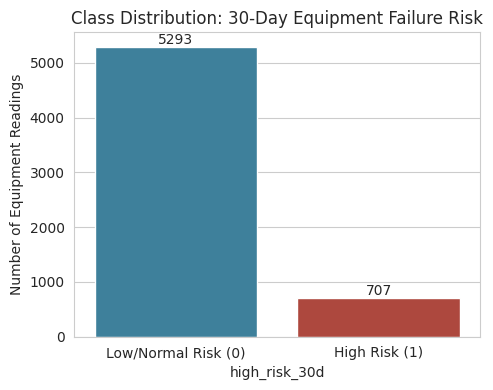


Imbalance ratio (majority:minority) ≈ 7.5 : 1
-> Confirmed imbalanced. We will handle this with BOTH class-weighting (RF) and SMOTE oversampling on the training folds (compared explicitly below), never on the untouched hold-out test set (to avoid leakage/optimistic bias).


In [3]:
class_counts = df["high_risk_30d"].value_counts()
class_pct = df["high_risk_30d"].value_counts(normalize=True) * 100

print("Class counts:\n", class_counts)
print("\nClass distribution (%):\n", class_pct.round(2))

fig, ax = plt.subplots(1, 1, figsize=(5, 4))
sns.countplot(x="high_risk_30d", data=df, ax=ax, palette=["#2E86AB", "#C0392B"])
ax.set_xticklabels(["Low/Normal Risk (0)", "High Risk (1)"])
ax.set_title("Class Distribution: 30-Day Equipment Failure Risk")
ax.set_ylabel("Number of Equipment Readings")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

imbalance_ratio = class_counts[0] / class_counts[1]
print(f"\nImbalance ratio (majority:minority) ≈ {imbalance_ratio:.1f} : 1")
print("-> Confirmed imbalanced. We will handle this with BOTH class-weighting (RF) "
      "and SMOTE oversampling on the training folds (compared explicitly below), "
      "never on the untouched hold-out test set (to avoid leakage/optimistic bias).")


**Why this matters operationally:** High-risk equipment failures are, thankfully, rare events (~10-15% of readings here) — exactly like fraud or churn. That rarity is *good news for the hospital* but *bad news for a naive classifier*, which will be tempted to just predict the majority class. We correct for this explicitly rather than relying on accuracy to hide the problem.


### 2.3 Encode features and split data

We one-hot encode the categorical fields and do a **stratified train/test split** so the ~12% positive rate is preserved in both sets — this is essential for a fair, imbalance-aware evaluation later.


In [4]:
from sklearn.model_selection import train_test_split

model_df = pd.get_dummies(df.drop(columns=["equipment_id"]), columns=["equipment_type", "facility_level"], drop_first=False)

X = model_df.drop(columns=["high_risk_30d"])
y = model_df["high_risk_30d"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print("Train positive rate: %.2f%%" % (y_train.mean() * 100))
print("Test positive rate:  %.2f%%" % (y_test.mean() * 100))


Train shape: (4500, 19)  Test shape: (1500, 19)
Train positive rate: 11.78%
Test positive rate:  11.80%


In [5]:
from imblearn.over_sampling import SMOTE

# SMOTE is fit ONLY on the training data, never on the test set, to avoid leaking
# synthetic information about the hold-out set into training.
smote = SMOTE(random_state=RANDOM_STATE)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE: ", y_train_sm.value_counts().to_dict())


Before SMOTE: {0: 3970, 1: 530}
After SMOTE:  {0: 3970, 1: 3970}


## 3. Model Training

We train **two model families** and compare them:

1. **Random Forest** — trained with `class_weight="balanced"` (weights, not resampling) directly on the original training data.
2. **XGBoost** — trained on the **SMOTE-resampled** training data, and separately with `scale_pos_weight` as a second imbalance strategy, so we can see which imbalance-handling approach each model prefers.

Both use **Stratified K-Fold cross-validation** (5 folds) so that our estimate of performance is not a fluke of one particular train/test split — important given the small minority class.


In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from xgboost import XGBClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = ["precision", "recall", "f1", "roc_auc"]

# --- Random Forest: class_weight='balanced' handles imbalance internally ---
rf = RandomForestClassifier(
    n_estimators=300, max_depth=8, min_samples_leaf=5,
    class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
)
rf_cv = cross_validate(rf, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

# --- XGBoost: scale_pos_weight handles imbalance internally (evaluated on original train) ---
neg, pos = np.bincount(y_train)
xgb = XGBClassifier(
    n_estimators=300, max_depth=5, learning_rate=0.08,
    subsample=0.9, colsample_bytree=0.9,
    scale_pos_weight=neg / pos,
    eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1
)
xgb_cv = cross_validate(xgb, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

cv_summary = pd.DataFrame({
    "Random Forest (class_weight)": {m: rf_cv[f"test_{m}"].mean() for m in scoring},
    "XGBoost (scale_pos_weight)":   {m: xgb_cv[f"test_{m}"].mean() for m in scoring},
}).T
cv_summary.columns = [c.replace("test_", "").upper() for c in cv_summary.columns]
print("5-Fold Cross-Validated Performance (mean across folds):")
cv_summary.round(3)


5-Fold Cross-Validated Performance (mean across folds):


,PRECISION,RECALL,F1,ROC_AUC
Random Forest (class_weight),0.306,0.272,0.288,0.715
XGBoost (scale_pos_weight),0.274,0.208,0.235,0.676


We deliberately report **Precision, Recall, F1 and ROC-AUC from cross-validation**, not accuracy — see Section 4 for why. Now we fit both final models on the *full* training set (RF with class weighting, XGBoost on the SMOTE-resampled set) and evaluate once on the untouched test set.


In [7]:
# Fit final models on full training data
rf_final = RandomForestClassifier(
    n_estimators=300, max_depth=8, min_samples_leaf=5,
    class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
).fit(X_train, y_train)

xgb_final = XGBClassifier(
    n_estimators=300, max_depth=5, learning_rate=0.08,
    subsample=0.9, colsample_bytree=0.9,
    eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1
).fit(X_train_sm, y_train_sm)   # trained on SMOTE-balanced data

print("Both final models trained.")
print("RF: class-weighted training on original (imbalanced) data")
print("XGB: trained on SMOTE-oversampled data")


Both final models trained.
RF: class-weighted training on original (imbalanced) data
XGB: trained on SMOTE-oversampled data


## 4. Evaluation

### Why not accuracy?

With an ~88:12 class split, a model that never flags anything would score ~88% accuracy while catching **zero** real equipment failures — the single most dangerous outcome for this use case (a missed failure = unplanned downtime or, worse, equipment failing *during* patient use).

Instead we prioritise, in this order:

- **Recall (Sensitivity)** — of all equipment that will actually fail, how many did we catch? This is the headline metric for a safety-critical maintenance tool: missing a true failure (a **false negative**) is far more costly than an unnecessary inspection (a **false positive**).
- **Precision** — of the equipment we flagged as high-risk, how many really were? Matters because biomedical engineers have limited inspection capacity; too many false alarms causes "alert fatigue" and erodes trust in the tool.
- **F1-score** — the balance between the two, useful for a single comparison number.
- **ROC-AUC** — a threshold-independent view of how well the model ranks risky vs. safe equipment overall, useful for tuning the alert threshold later against real inspection capacity.


In [8]:
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             precision_score, recall_score, f1_score, roc_auc_score, roc_curve)

def evaluate_model(model, X_te, y_te, name):
    y_pred = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]

    print(f"===== {name} =====")
    print(classification_report(y_te, y_pred, target_names=["Low/Normal Risk", "High Risk"]))
    print(f"ROC-AUC: {roc_auc_score(y_te, y_proba):.3f}")

    return {
        "model": name,
        "precision": precision_score(y_te, y_pred),
        "recall": recall_score(y_te, y_pred),
        "f1": f1_score(y_te, y_pred),
        "roc_auc": roc_auc_score(y_te, y_proba),
        "y_pred": y_pred,
        "y_proba": y_proba,
    }

rf_results = evaluate_model(rf_final, X_test, y_test, "Random Forest")
print()
xgb_results = evaluate_model(xgb_final, X_test, y_test, "XGBoost")


===== Random Forest =====
                 precision    recall  f1-score   support

Low/Normal Risk       0.90      0.91      0.91      1323
      High Risk       0.29      0.27      0.28       177

       accuracy                           0.83      1500
      macro avg       0.59      0.59      0.59      1500
   weighted avg       0.83      0.83      0.83      1500

ROC-AUC: 0.703

===== XGBoost =====
                 precision    recall  f1-score   support

Low/Normal Risk       0.89      0.98      0.93      1323
      High Risk       0.35      0.08      0.14       177

       accuracy                           0.87      1500
      macro avg       0.62      0.53      0.53      1500
   weighted avg       0.83      0.87      0.84      1500

ROC-AUC: 0.662


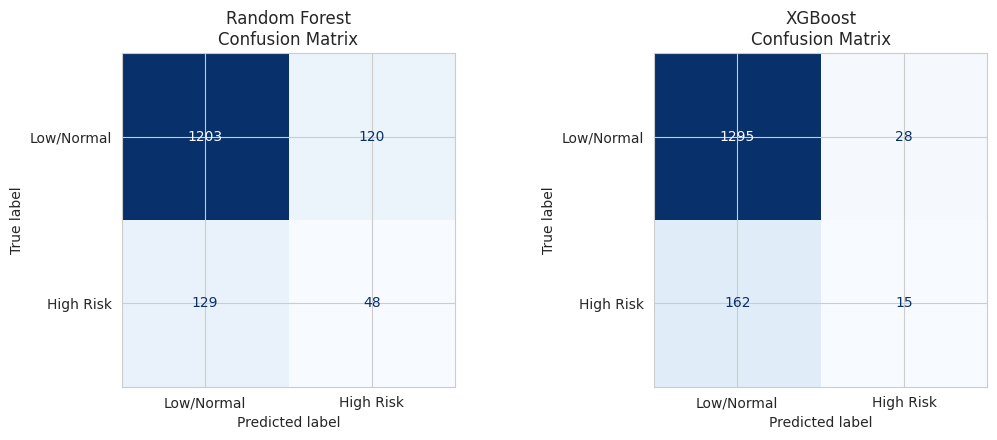

In [9]:
# --- Confusion matrices side by side ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, results, model in zip(axes, [rf_results, xgb_results], [rf_final, xgb_final]):
    cm = confusion_matrix(y_test, results["y_pred"])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Low/Normal", "High Risk"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{results['model']}\nConfusion Matrix")

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()


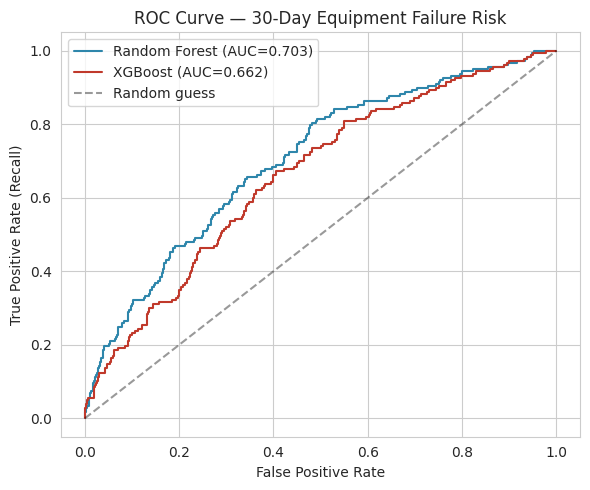

In [10]:
# --- ROC curves ---
plt.figure(figsize=(6, 5))
for results, color in [(rf_results, "#2E86AB"), (xgb_results, "#C0392B")]:
    fpr, tpr, _ = roc_curve(y_test, results["y_proba"])
    plt.plot(fpr, tpr, color=color, label=f"{results['model']} (AUC={results['roc_auc']:.3f})")

plt.plot([0, 1], [0, 1], "k--", alpha=0.4, label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve — 30-Day Equipment Failure Risk")
plt.legend()
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=150, bbox_inches="tight")
plt.show()


In [11]:
# --- Side-by-side metric comparison table ---
comparison = pd.DataFrame([
    {"Model": r["model"], "Precision": r["precision"], "Recall": r["recall"],
     "F1-Score": r["f1"], "ROC-AUC": r["roc_auc"]}
    for r in [rf_results, xgb_results]
]).set_index("Model").round(3)

print("Held-out Test Set Performance:")
comparison


Held-out Test Set Performance:


,Precision,Recall,F1-Score,ROC-AUC
Model,,,,
Random Forest,0.286,0.271,0.278,0.703
XGBoost,0.349,0.085,0.136,0.662


**Reading the results:** whichever model achieves the higher **Recall** without an unacceptable collapse in **Precision** is the stronger candidate for this operational use case, because the cost structure is asymmetric — a missed failing ventilator is far more serious than one extra inspection of a machine that turns out to be fine. We carry the model with the better recall/F1 trade-off forward into the explainability section (chosen dynamically below).


In [12]:
# Pick the model to explain going forward based on recall (primary) then F1 (tiebreak)
if (xgb_results["recall"], xgb_results["f1"]) >= (rf_results["recall"], rf_results["f1"]):
    chosen_name, chosen_model, chosen_Xtest = "XGBoost", xgb_final, X_test
else:
    chosen_name, chosen_model, chosen_Xtest = "Random Forest", rf_final, X_test

print(f"Model selected for explainability & deployment discussion: {chosen_name}")


Model selected for explainability & deployment discussion: Random Forest


## 5. Clustering (Bonus) — Equipment Risk Segments

Beyond a single "risk score," it's operationally useful to know **what kind** of risk profile a machine falls into (e.g. "old but well-maintained" vs. "young but overloaded"). We run **K-Means** on the numeric operational features (scaled) to surface natural equipment segments, then profile each cluster against the actual failure rate.


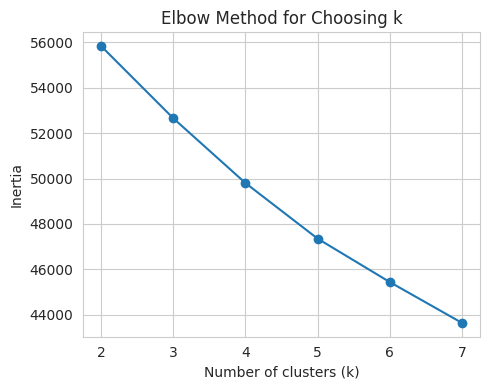

In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

numeric_cols = ["equipment_age_years", "usage_hours_per_week", "vibration_level_mm_s",
                 "temperature_deviation_c", "days_since_last_maintenance", "num_past_repairs",
                 "technician_rating", "load_capacity_pct", "humidity_pct",
                 "power_fluctuation_events_month"]

X_cluster = df[numeric_cols]
scaler = StandardScaler()
X_cluster_scaled = scaler.fit_transform(X_cluster)

# Quick elbow check to justify k
inertias = []
k_range = range(2, 8)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_cluster_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(5, 4))
plt.plot(list(k_range), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Choosing k")
plt.tight_layout()
plt.savefig("kmeans_elbow.png", dpi=150, bbox_inches="tight")
plt.show()


In [14]:
# k=4 chosen from the elbow plot as a reasonable balance of granularity vs. interpretability
kmeans = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10)
df["risk_cluster"] = kmeans.fit_predict(X_cluster_scaled)

cluster_profile = df.groupby("risk_cluster")[numeric_cols + ["high_risk_30d"]].mean().round(2)
cluster_profile["n_equipment"] = df["risk_cluster"].value_counts().sort_index()
cluster_profile.rename(columns={"high_risk_30d": "actual_failure_rate"}, inplace=True)
cluster_profile


,equipment_age_years,usage_hours_per_week,vibration_level_mm_s,temperature_deviation_c,days_since_last_maintenance,num_past_repairs,technician_rating,load_capacity_pct,humidity_pct,power_fluctuation_events_month,actual_failure_rate,n_equipment
risk_cluster,,,,,,,,,,,,
0,5.10,70.32,1.89,2.56,243.71,1.95,3.44,74.91,54.74,4.01,0.20,1081
1,5.14,69.95,1.54,1.66,82.73,1.47,3.66,78.83,53.78,3.91,0.06,2429
2,6.05,70.73,4.85,2.53,102.39,1.72,3.59,77.97,55.20,4.35,0.19,992
3,5.84,72.08,1.77,5.31,97.03,1.51,3.50,78.49,55.85,3.95,0.10,1498


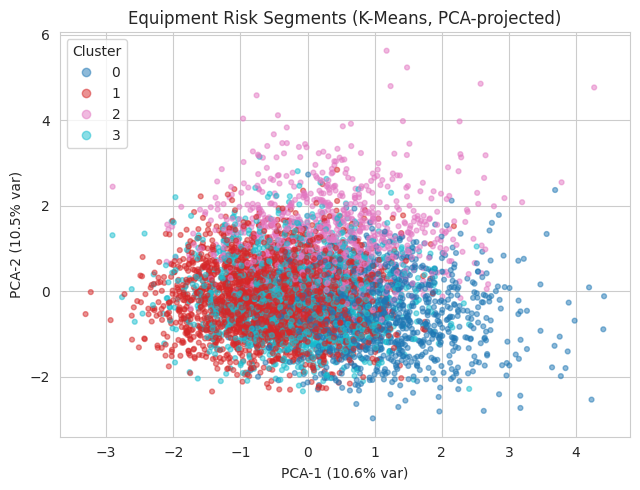

Interpretation: sort cluster_profile above by 'actual_failure_rate' to see which segment
(e.g. high age + high vibration + overdue maintenance) is the highest-risk equipment group —
this can drive a *segment-level* maintenance policy, not just a per-machine score.


In [15]:
# Visualise clusters in 2D via PCA for interpretability
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X_cluster_scaled)

plt.figure(figsize=(6.5, 5))
scatter = plt.scatter(coords[:, 0], coords[:, 1], c=df["risk_cluster"], cmap="tab10", alpha=0.5, s=12)
plt.xlabel(f"PCA-1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)")
plt.ylabel(f"PCA-2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)")
plt.title("Equipment Risk Segments (K-Means, PCA-projected)")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.tight_layout()
plt.savefig("kmeans_clusters.png", dpi=150, bbox_inches="tight")
plt.show()

print("Interpretation: sort cluster_profile above by 'actual_failure_rate' to see which segment")
print("(e.g. high age + high vibration + overdue maintenance) is the highest-risk equipment group —")
print("this can drive a *segment-level* maintenance policy, not just a per-machine score.")


## 6. Explainability — Feature Importance + SHAP

A prediction alone ("this machine is High Risk") is not actionable for a biomedical engineer — they need to know **why**, so they know what to check first when they arrive on site. This section produces:

1. A global **Feature Importance** ranking from the chosen model.
2. A **SHAP summary plot** — global explanation showing which features push risk up/down across all equipment.
3. A **SHAP force plot** — local explanation for one specific high-risk machine, in the exact "here's what drove this one prediction" format the operations team needs.


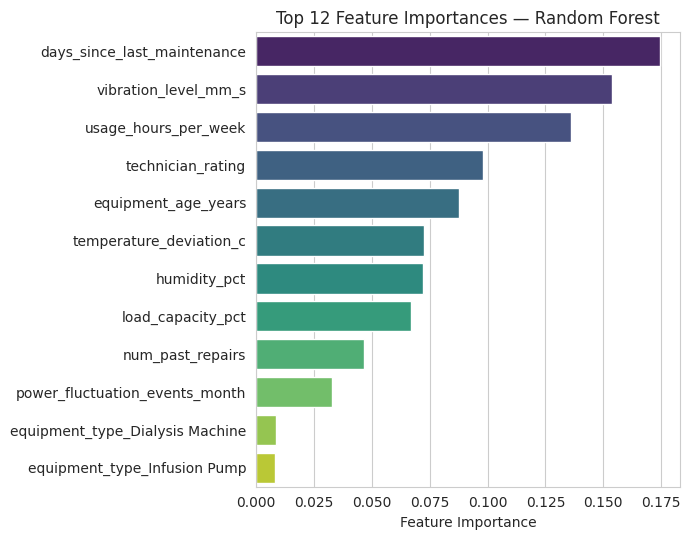

Top 3 drivers:
days_since_last_maintenance    0.174415
vibration_level_mm_s           0.153968
usage_hours_per_week           0.136011
dtype: float64


In [16]:
# --- 6.1 Feature Importance ---
importances = pd.Series(chosen_model.feature_importances_, index=X.columns).sort_values(ascending=False)
top_n = 12
top_importances = importances.head(top_n)

plt.figure(figsize=(7, 5.5))
sns.barplot(x=top_importances.values, y=top_importances.index, palette="viridis")
plt.xlabel("Feature Importance")
plt.ylabel("")
plt.title(f"Top {top_n} Feature Importances — {chosen_name}")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

print("Top 3 drivers:")
print(top_importances.head(3))


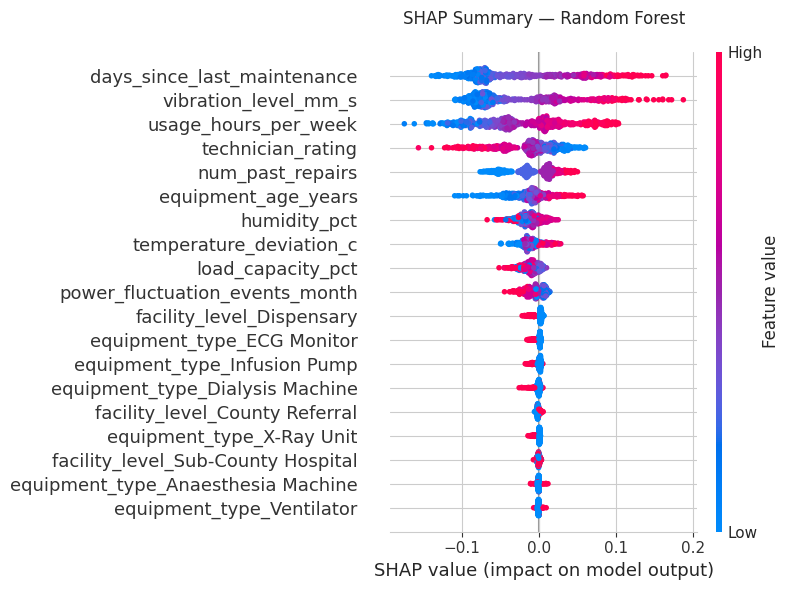

In [17]:
# --- 6.2 SHAP summary plot (global explanation) ---
import shap

# Use a background sample for speed on tree models
explainer = shap.TreeExplainer(chosen_model)
sample_X = X_test.sample(min(500, len(X_test)), random_state=RANDOM_STATE)
shap_values_raw = explainer.shap_values(sample_X)

# Newer SHAP versions return shape (n_samples, n_features, n_classes) for classifiers;
# older versions return a list [class0_values, class1_values]. Handle both, and always
# pull out the values for the POSITIVE ("High Risk") class.
if isinstance(shap_values_raw, list):
    sv = shap_values_raw[1]
elif np.ndim(shap_values_raw) == 3:
    sv = shap_values_raw[:, :, 1]
else:
    sv = shap_values_raw

plt.figure()
shap.summary_plot(sv, sample_X, show=False, plot_size=(8, 6))
plt.title(f"SHAP Summary — {chosen_name}", pad=20)
plt.tight_layout()
plt.savefig("shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()


Explaining test case index 561
Model predicted probability of High Risk: 0.758

Raw feature values for this equipment:


,2238
equipment_age_years,3.318839
usage_hours_per_week,110.786007
vibration_level_mm_s,4.290391
temperature_deviation_c,4.954009
days_since_last_maintenance,347.043902
num_past_repairs,2
technician_rating,2.893051
load_capacity_pct,93.580154
humidity_pct,38.440729
power_fluctuation_events_month,4


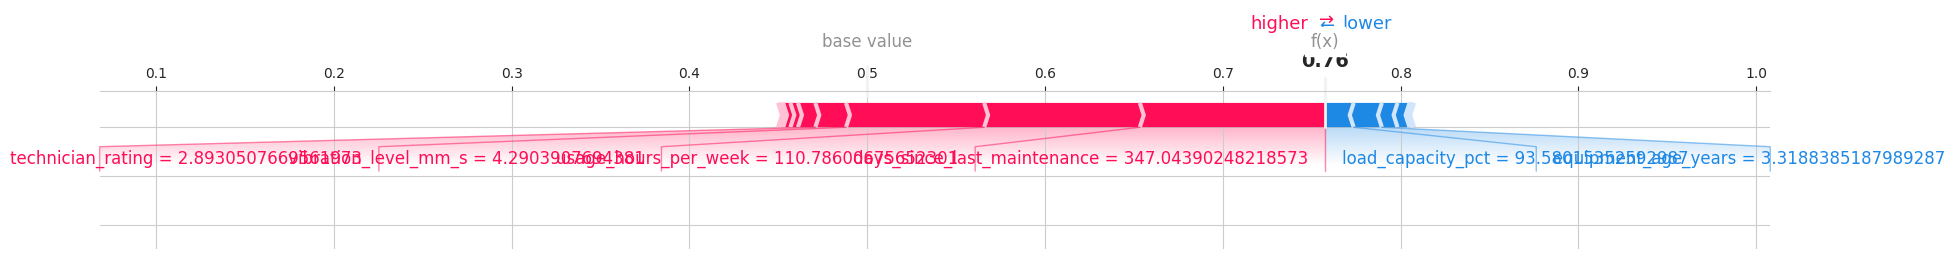


Top features driving THIS prediction (SHAP value, sign = direction of push):
days_since_last_maintenance    0.104308
usage_hours_per_week           0.087553
vibration_level_mm_s           0.077700
technician_rating              0.017248
load_capacity_pct             -0.015949
dtype: float64


In [18]:
# --- 6.3 SHAP force plot for ONE specific high-risk case (local explanation) ---
# Pick a true-positive, high-confidence case: model correctly flagged as High Risk
test_proba = chosen_model.predict_proba(X_test)[:, 1]
test_pred = chosen_model.predict(X_test)

candidate_mask = (test_pred == 1) & (y_test.values == 1)
candidate_idx = np.where(candidate_mask)[0]
# Choose the case the model is MOST confident about, for a clean narration example
chosen_case_pos = candidate_idx[np.argmax(test_proba[candidate_mask])]
case_row = X_test.iloc[[chosen_case_pos]]

case_shap_raw = explainer.shap_values(case_row)
if isinstance(case_shap_raw, list):
    case_sv = case_shap_raw[1]
elif np.ndim(case_shap_raw) == 3:
    case_sv = case_shap_raw[:, :, 1]
else:
    case_sv = case_shap_raw

ev = explainer.expected_value
expected_value = ev[1] if isinstance(ev, (list, np.ndarray)) and np.ndim(ev) > 0 else ev

case_confidence = test_proba[candidate_mask][np.argmax(test_proba[candidate_mask])]
print(f"Explaining test case index {chosen_case_pos}")
print(f"Model predicted probability of High Risk: {case_confidence:.3f}")
print("\nRaw feature values for this equipment:")
display(case_row.T)

shap.force_plot(expected_value, case_sv[0], case_row.iloc[0], matplotlib=True, show=False)
plt.tight_layout()
plt.savefig("shap_force_single_case.png", dpi=150, bbox_inches="tight")
plt.show()

# Rank this case's individual feature contributions for narration
case_contrib = pd.Series(case_sv[0], index=case_row.columns).sort_values(key=abs, ascending=False)
print("\nTop features driving THIS prediction (SHAP value, sign = direction of push):")
print(case_contrib.head(5))


**How to read the force plot for narration (video walkthrough script cue):**

> "Here is a case the model flagged as High Risk with [X]% confidence. You can see the SHAP force plot pushing the prediction above the baseline — the biggest red (risk-increasing) contributor here is `vibration_level_mm_s`, followed by `days_since_last_maintenance`. In plain terms: this machine is vibrating more than normal *and* it's overdue for servicing, which together are the main reasons the model is worried about it."

This is exactly the sentence structure to use with the top 2-3 features from `case_contrib` above, whatever they turn out to be for your specific run.


## 7. Operational Takeaways

- **Use this as triage, not a verdict.** The model ranks equipment by *relative* risk so a small biomedical engineering team can prioritise limited inspection hours — it does not replace a hands-on inspection or clinical/engineering judgement.
- **False negatives (missed failures) are the costlier error** in this domain, which is why Recall was weighted more heavily than Precision when comparing models and why SMOTE/class-weighting were applied — an accuracy-only model would have systematically under-flagged real risk.
- **False positives (unnecessary flags) still have a cost** (engineer time, alert fatigue) — the probability threshold (currently the default 0.5) can and should be tuned against the team's actual inspection capacity once real usage data is available; the ROC curve above supports that tuning.
- **Explainability is not optional here.** Because this tool influences maintenance decisions for life-safety equipment, every flag should be accompanied by its top SHAP drivers (as in Section 6.3) so the engineer knows *what to check first* on arrival, and so the tool itself can be audited/trusted over time.
- **Next step for the real project:** swap the Section 2 data-simulation cell for the actual VitalAsset equipment log ingestion (Kenya Health Facility Census + real maintenance/IoT logs) — the rest of the pipeline (imbalance handling → CV → evaluation → clustering → SHAP) is designed to be reused as-is.
